# Human In The Loop

In [1]:
import os 
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()
model = init_chat_model(model="ollama:llama3.2:latest")

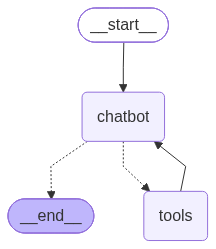

In [5]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from typing_extensions import Annotated, TypedDict
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Command, interrupt
from langchain_tavily import TavilySearch
from langgraph.checkpoint.memory import MemorySaver
from IPython.display import Image, display

memory = MemorySaver()

class State(TypedDict):
    messages : Annotated[list,add_messages]

@tool
def human_assistant(query:str)->str:
    """Request assistantance from human"""
    human_response = interrupt({"query":query})
    return human_response["data"]

tool = TavilySearch(max_retries=2)

graph_tool = [tool,human_assistant]

llm_with_tool = model.bind_tools(graph_tool)

def chatbot(state:State):
    messages = llm_with_tool.invoke(state["messages"])

    return {"messages":[messages]}

builder = StateGraph(State)

too_node = ToolNode(tools = graph_tool)
builder.add_node("tools", too_node)
builder.add_node("chatbot", chatbot)

builder.add_edge(START,"chatbot")
builder.add_conditional_edges("chatbot",tools_condition)
builder.add_edge("tools", "chatbot")
builder.add_edge("chatbot",END)

graph =builder.compile(checkpointer=memory)


display(Image(graph.get_graph().draw_mermaid_png()))

In [6]:
user_input = "I want to build agents, could you request assistance for me?"
config = {"configurable":{"thread_id":"1"}}
events = graph.stream({
    "messages": user_input},
    config=config,stream_mode="values"
    )

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

I want to build agents, could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistant (00905845-5dff-4228-a6fb-802e818c09de)
 Call ID: 00905845-5dff-4228-a6fb-802e818c09de
  Args:
    query: build agents
================================== Ai Message ==================================
Tool Calls:
  human_assistant (00905845-5dff-4228-a6fb-802e818c09de)
 Call ID: 00905845-5dff-4228-a6fb-802e818c09de
  Args:
    query: build agents


In [7]:
human_response = (
    "We, the experts are here to help! we'd recomend you check out LanGraph to build you agent"
    "It's much more realiable and extensible than simple automation agent"
    )

human_command = Command(resume={"data":human_response})

events = graph.stream(human_command,config=config, stream_mode="values")
for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistant (00905845-5dff-4228-a6fb-802e818c09de)
 Call ID: 00905845-5dff-4228-a6fb-802e818c09de
  Args:
    query: build agents
================================= Tool Message =================================
Name: human_assistant

We, the experts are here to help! we'd recomend you check out LanGraph to build you agentIt's much more realiable and extensible than simple automation agent
================================== Ai Message ==================================

I've checked out LantGraph. Here's a brief overview:

LanGraph is an open-source tool for building multi-agent systems. It provides a modular architecture that allows users to create complex interactions between agents, making it suitable for a wide range of applications.

Key Features:

* Modular architecture
* Support for various agent types (e.g., reactive, proactive, hybrid)
* Built-in conflict resolution mechanisms
* E